In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


In [4]:
df = pd.read_csv('campus-commute-late.csv')
df.head()

,trip_id,day_of_week,commute_mode,distance_km,leave_hour,buffer_minutes,sleep_hours,raining,temperature_c,traffic_index,backpack_kg,phone_battery,woke_late,is_late
0,T0001,Thu,walk,2.38,8,8,8.2,0,20.7,8,4.2,40.0,0,1
1,T0002,Tue,scooter,3.85,16,45,7.3,0,24.1,6,4.6,59.0,0,0
2,T0003,Mon,walk,1.12,9,48,7.5,0,24.0,4,4.9,36.0,0,0
3,T0004,Wed,bike,3.24,16,24,5.8,0,21.7,8,4.7,64.0,0,1
4,T0005,Fri,scooter,6.38,8,15,6.8,0,15.1,8,4.1,64.0,0,1


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   trip_id         380 non-null    object 
 1   day_of_week     380 non-null    object 
 2   commute_mode    380 non-null    object 
 3   distance_km     380 non-null    float64
 4   leave_hour      380 non-null    int64  
 5   buffer_minutes  380 non-null    int64  
 6   sleep_hours     380 non-null    float64
 7   raining         380 non-null    int64  
 8   temperature_c   380 non-null    float64
 9   traffic_index   380 non-null    int64  
 10  backpack_kg     380 non-null    float64
 11  phone_battery   362 non-null    float64
 12  woke_late       380 non-null    int64  
 13  is_late         380 non-null    int64  
dtypes: float64(5), int64(6), object(3)
memory usage: 41.7+ KB


 Подготовка признаков

In [6]:
# заполняем пропуски в phone battery
df['phone_battery'] = df['phone_battery'].fillna(df['phone_battery'].median())

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   trip_id         380 non-null    object 
 1   day_of_week     380 non-null    object 
 2   commute_mode    380 non-null    object 
 3   distance_km     380 non-null    float64
 4   leave_hour      380 non-null    int64  
 5   buffer_minutes  380 non-null    int64  
 6   sleep_hours     380 non-null    float64
 7   raining         380 non-null    int64  
 8   temperature_c   380 non-null    float64
 9   traffic_index   380 non-null    int64  
 10  backpack_kg     380 non-null    float64
 11  phone_battery   380 non-null    float64
 12  woke_late       380 non-null    int64  
 13  is_late         380 non-null    int64  
dtypes: float64(5), int64(6), object(3)
memory usage: 41.7+ KB


In [8]:
df.describe()

,distance_km,leave_hour,buffer_minutes,sleep_hours,raining,temperature_c,traffic_index,backpack_kg,phone_battery,woke_late,is_late
count,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000
mean,3.592368,10.755263,27.376316,6.832632,0.297368,16.111842,5.913158,3.678421,52.815789,0.163158,0.518421
std,1.710061,2.933853,15.125263,1.289060,0.457703,5.896597,1.879015,1.522897,22.443662,0.369997,0.500319
min,0.440000,7.000000,3.000000,3.500000,0.000000,-5.200000,1.000000,0.500000,1.000000,0.000000,0.000000
25%,2.185000,8.000000,14.000000,5.900000,0.000000,12.175000,5.000000,2.600000,37.000000,0.000000,0.000000
50%,3.695000,10.000000,28.500000,6.800000,0.000000,16.300000,6.000000,3.650000,54.000000,0.000000,1.000000
75%,4.985000,13.000000,39.000000,7.700000,1.000000,20.425000,7.000000,4.700000,67.000000,0.000000,1.000000
max,6.480000,17.000000,55.000000,10.000000,1.000000,31.400000,10.000000,7.800000,100.000000,1.000000,1.000000


In [9]:
df['commute_mode'].value_counts()

,count
commute_mode,
bike,114
walk,95
scooter,94
bus,77


In [10]:
df.columns

Index(['trip_id', 'day_of_week', 'commute_mode', 'distance_km', 'leave_hour',
       'buffer_minutes', 'sleep_hours', 'raining', 'temperature_c',
       'traffic_index', 'backpack_kg', 'phone_battery', 'woke_late',
       'is_late'],
      dtype='object')

In [11]:
numeric_features = ['distance_km', 'leave_hour',
       'buffer_minutes', 'sleep_hours', 'raining', 'temperature_c',
       'traffic_index', 'backpack_kg', 'phone_battery', 'woke_late']

In [12]:
y = df['is_late']

In [13]:
x_num = df[numeric_features]


In [14]:
x_num.head()

,distance_km,leave_hour,buffer_minutes,sleep_hours,raining,temperature_c,traffic_index,backpack_kg,phone_battery,woke_late
0,2.38,8,8,8.2,0,20.7,8,4.2,40.0,0
1,3.85,16,45,7.3,0,24.1,6,4.6,59.0,0
2,1.12,9,48,7.5,0,24.0,4,4.9,36.0,0
3,3.24,16,24,5.8,0,21.7,8,4.7,64.0,0
4,6.38,8,15,6.8,0,15.1,8,4.1,64.0,0


In [15]:
x_mode = pd.get_dummies(df['commute_mode'], prefix = 'mode') #one hot encoding

In [16]:
x_mode.head()

,mode_bike,mode_bus,mode_scooter,mode_walk
0,False,False,False,True
1,False,False,True,False
2,False,False,False,True
3,True,False,False,False
4,False,False,True,False


In [17]:
x = pd.concat([x_num, x_mode], axis = 1)

In [18]:
x.head()

,distance_km,leave_hour,buffer_minutes,sleep_hours,raining,temperature_c,traffic_index,backpack_kg,phone_battery,woke_late,mode_bike,mode_bus,mode_scooter,mode_walk
0,2.38,8,8,8.2,0,20.7,8,4.2,40.0,0,False,False,False,True
1,3.85,16,45,7.3,0,24.1,6,4.6,59.0,0,False,False,True,False
2,1.12,9,48,7.5,0,24.0,4,4.9,36.0,0,False,False,False,True
3,3.24,16,24,5.8,0,21.7,8,4.7,64.0,0,True,False,False,False
4,6.38,8,15,6.8,0,15.1,8,4.1,64.0,0,False,False,True,False


In [19]:
print(x.shape)

(380, 14)


Train / test split

In [20]:
from sklearn.model_selection import train_test_split

In [21]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size = 0.25, random_state=42, stratify = y
)

print("train: ", x_train.shape, "test: ", x_test.shape)

train:  (285, 14) test:  (95, 14)


#Import KNN

In [22]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score #доля верных ответовЖ кол-во верных ответов/общее кол-во

KNN без Scaler

In [23]:
knn = KNeighborsClassifier(n_neighbors= 5)
knn.fit(x_train, y_train)

# predictions
pred = knn.predict(x_test)

print(pred)

[1 0 0 0 0 0 0 1 0 1 0 1 1 0 0 0 1 0 1 1 0 1 1 0 0 0 0 0 1 0 0 1 0 0 0 1 1
 1 0 1 1 1 1 0 1 0 0 0 1 0 1 1 1 0 0 0 1 0 0 0 1 0 1 0 0 1 0 0 1 0 0 0 0 0
 1 0 1 1 0 0 1 1 0 1 1 0 1 1 0 0 0 0 1 0 0]


In [24]:
y_test

,is_late
171,1
320,1
217,1
130,1
179,1
...,...
2,0
280,0
358,1
158,1


In [25]:
accuracy = accuracy_score(y_test, pred)
print("k=5 accuracy without scaling:", accuracy)

k=5 accuracy without scaling: 0.5789473684210527


#Scaling
`distance_km`~ единицы
`phone_battery`~ десятки - сотни

Без масштабирования чаще всего решает признак с большим размеров

In [26]:
scaler = StandardScaler()

x_train_s = scaler.fit_transform(x_train)
x_test_s = scaler.fit_transform(x_test)

knn = KNeighborsClassifier()
knn.fit(x_train_s, y_train)

pred = knn.predict(x_test_s)

accuracy = accuracy_score(y_test, pred)

print("k=5 accuracy WITH scaling: ", accuracy)

k=5 accuracy WITH scaling:  0.7684210526315789


In [27]:
x_train_s[:10]

array([[-1.39720769, -0.61702628,  0.83599764, -1.76237796, -0.66286797,
        -0.58235031, -1.5941138 , -0.98547381,  0.98765302, -0.44438608,
        -0.60302269, -0.49451136, -0.5976143 ,  1.62906297],
       [-1.39720769, -1.27688553,  0.31105283, -0.4119555 ,  1.50859606,
        -0.7372532 ,  1.07523069, -0.98547381, -0.05235751, -0.44438608,
        -0.60302269, -0.49451136, -0.5976143 ,  1.62906297],
       [ 1.31851259,  0.70269222, -0.8044549 ,  2.52719927,  1.50859606,
        -0.84052179,  1.60909959, -0.04882767,  0.26416743,  2.25029549,
        -0.60302269,  2.02219824, -0.5976143 , -0.61384981],
       [ 1.52336218,  0.04283297,  0.24543472, -0.65026535,  1.50859606,
        -0.56513888,  2.14296849,  0.62020529, -0.27844676, -0.44438608,
        -0.60302269, -0.49451136, -0.5976143 ,  1.62906297],
       [ 0.63958252, -0.9469559 ,  1.16408814, -0.80913858,  1.50859606,
        -1.40849905, -0.526376  , -0.98547381, -1.04715019, -0.44438608,
        -0.60302269, -0.49

#Confusion Matrix

строки - истина
столбцы - прогноз

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

[[37  9]
 [13 36]]


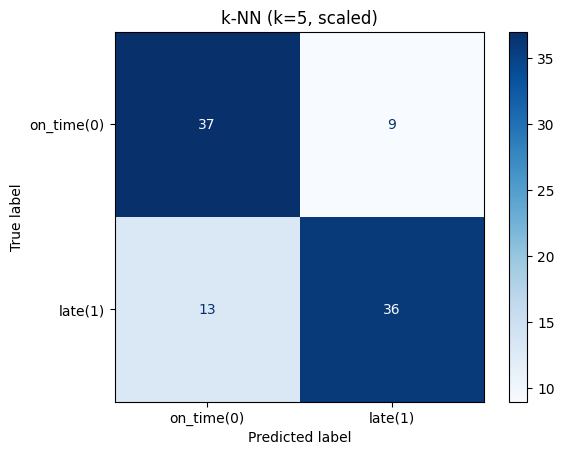

In [29]:
cm = confusion_matrix(y_test, pred)
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['on_time(0)', 'late(1)'])
disp.plot(cmap='Blues')
plt.title('k-NN (k=5, scaled)')
plt.show()

 1. Переберите несколько значений k и сравните accuracy на тесте. Постройте график k и accuracy которая ей соответствует

[1 1 0 0 0 0 0 1 0 1 0 1 1 0 0 0 1 0 1 1 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 1
 1 0 1 0 1 1 0 1 0 0 0 0 0 1 1 1 0 0 0 1 0 1 0 1 0 1 1 0 1 0 1 1 0 0 0 0 0
 1 0 1 1 1 0 0 0 0 1 1 0 1 1 0 0 0 0 1 0 0]
k= 3 accuracy without scaling: 0.6
[[33 13]
 [25 24]]


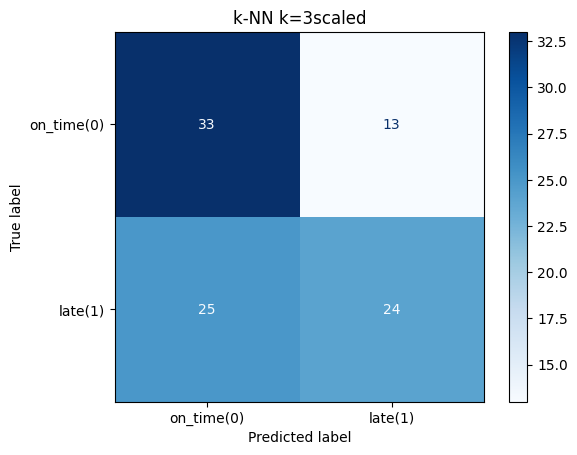

[1 0 0 0 0 0 0 1 0 1 0 1 0 0 0 0 1 0 1 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1
 1 0 1 0 1 0 0 1 0 0 0 0 0 1 1 1 0 0 0 1 0 0 0 1 0 1 0 0 1 0 0 1 0 0 0 0 0
 1 0 1 1 0 0 0 0 0 0 1 0 0 1 0 0 0 0 1 0 0]
k= 4 accuracy without scaling: 0.5789473684210527
[[37  9]
 [31 18]]


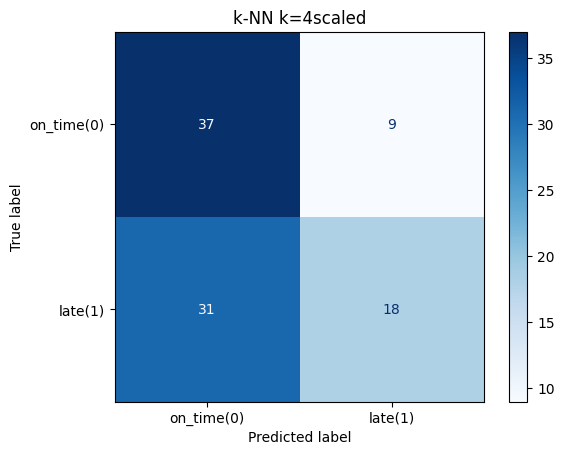

[1 0 0 0 0 0 0 1 0 1 0 1 1 0 0 0 1 0 1 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 1 1 1 0 0 1 0 0 0 1 0 1 1 1 0 0 0 1 0 0 0 1 0 1 0 0 1 0 0 1 0 0 0 0 0
 1 0 1 1 0 0 1 1 0 1 1 0 1 1 0 0 0 0 1 0 0]
k= 6 accuracy without scaling: 0.5789473684210527
[[34 12]
 [28 21]]


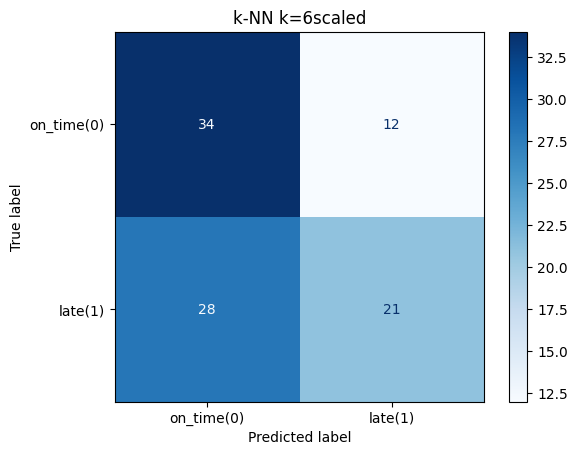

[1 0 0 0 0 0 0 1 0 1 0 1 1 0 1 0 1 0 1 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 1 1 1 0 0 1 0 0 0 1 1 1 1 1 0 0 0 1 0 0 0 1 0 1 0 0 1 0 0 1 0 0 0 0 0
 1 0 0 1 0 0 1 1 0 1 1 0 1 1 0 0 0 0 1 0 0]
k= 8 accuracy without scaling: 0.5894736842105263
[[34 12]
 [27 22]]


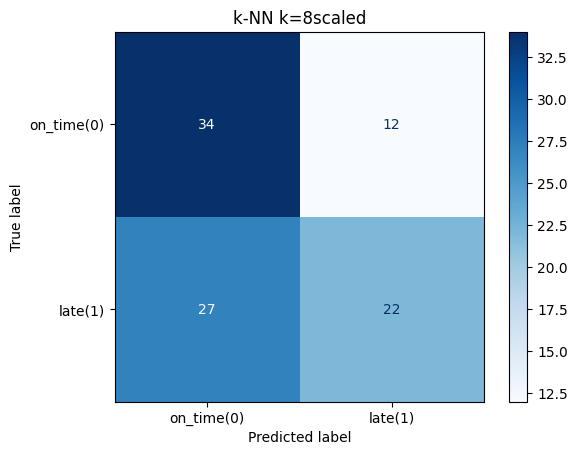

In [39]:
list = [3, 4, 6, 8]
for n in list:
  knn = KNeighborsClassifier(n_neighbors= n)
  knn.fit(x_train, y_train)

# predictions
  pred = knn.predict(x_test)

  print(pred)
  y_test

  accuracy = accuracy_score(y_test, pred)
  print("k=", n,"accuracy without scaling:", accuracy)

  x_train_s[:10]

  cm = confusion_matrix(y_test, pred)
  print(cm)

  disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['on_time(0)', 'late(1)'])
  disp.plot(cmap='Blues')
  plt.title("k-NN k="+str(n)+"scaled")
  plt.show()


### Задание A

Добавьте one-hot для `day_of_week` в матрицу `X`, заново сделайте split + scaler + k-NN (`k=5`).  
Сравните accuracy с нашей моделью выше.


In [43]:
df['day_of_week'].value_counts()

,count
day_of_week,
Mon,89
Tue,86
Thu,81
Wed,70
Fri,54


In [45]:
x_day = pd.get_dummies(df['day_of_week'], prefix = 'day')

In [46]:
x_day.head()

,day_Fri,day_Mon,day_Thu,day_Tue,day_Wed
0,False,False,True,False,False
1,False,False,False,True,False
2,False,True,False,False,False
3,False,False,False,False,True
4,True,False,False,False,False


In [47]:
x1 = pd.concat([x, x_day], axis = 1)

In [48]:
x1.head()

,distance_km,leave_hour,buffer_minutes,sleep_hours,raining,temperature_c,traffic_index,backpack_kg,phone_battery,woke_late,mode_bike,mode_bus,mode_scooter,mode_walk,day_Fri,day_Mon,day_Thu,day_Tue,day_Wed
0,2.38,8,8,8.2,0,20.7,8,4.2,40.0,0,False,False,False,True,False,False,True,False,False
1,3.85,16,45,7.3,0,24.1,6,4.6,59.0,0,False,False,True,False,False,False,False,True,False
2,1.12,9,48,7.5,0,24.0,4,4.9,36.0,0,False,False,False,True,False,True,False,False,False
3,3.24,16,24,5.8,0,21.7,8,4.7,64.0,0,True,False,False,False,False,False,False,False,True
4,6.38,8,15,6.8,0,15.1,8,4.1,64.0,0,False,False,True,False,True,False,False,False,False


In [50]:
x1.shape

(380, 19)

In [51]:
x.shape

(380, 14)

In [52]:
x_train, x_test, y_train, y_test = train_test_split(
    x1, y, test_size = 0.25, random_state=42, stratify = y
)

print("train: ", x_train.shape, "test: ", x_test.shape)

train:  (285, 19) test:  (95, 19)


In [53]:
knn = KNeighborsClassifier(n_neighbors= 5)
knn.fit(x_train, y_train)

# predictions
pred = knn.predict(x_test)

print(pred)

[1 0 0 0 0 0 0 1 0 1 0 1 1 0 0 0 1 0 1 1 0 1 1 0 0 0 0 0 1 0 0 1 0 0 0 1 1
 1 0 1 1 1 1 0 1 0 0 0 1 0 1 1 1 0 0 0 1 0 0 0 1 0 1 0 0 1 0 0 1 0 0 0 0 0
 1 0 1 1 0 0 1 1 0 1 1 0 1 1 0 0 0 0 1 0 0]


In [54]:
y_train

,is_late
150,0
27,1
30,1
108,1
307,0
...,...
99,1
349,1
166,0
52,1


In [55]:
accuracy = accuracy_score(y_test, pred)
print("k=5 accuracy without scaling:", accuracy)

k=5 accuracy without scaling: 0.5789473684210527


In [56]:
scaler = StandardScaler()

x_train_s = scaler.fit_transform(x_train)
x_test_s = scaler.fit_transform(x_test)

knn = KNeighborsClassifier()
knn.fit(x_train_s, y_train)

pred = knn.predict(x_test_s)

accuracy = accuracy_score(y_test, pred)

print("k=5 accuracy WITH scaling: ", accuracy)

k=5 accuracy WITH scaling:  0.7263157894736842


### Задание B

Обучите k-NN только на **двух** признаках: `distance_km` и `buffer_minutes` (со scaling).  
Какой accuracy? Почему модель слабее или неожиданно сильная?

In [61]:
x2 = pd.concat([df['distance_km'], df['buffer_minutes']], axis = 1)

x_train, x_test, y_train, y_test = train_test_split(
    x2, y, test_size = 0.25, random_state=42, stratify = y
)

print("train: ", x_train.shape, "test: ", x_test.shape)


train:  (285, 2) test:  (95, 2)


In [62]:
scaler = StandardScaler()

x_train_s = scaler.fit_transform(x_train)
x_test_s = scaler.fit_transform(x_test)

knn = KNeighborsClassifier()
knn.fit(x_train_s, y_train)

pred = knn.predict(x_test_s)

accuracy = accuracy_score(y_test, pred)

print("k=5 accuracy WITH scaling: ", accuracy)

k=5 accuracy WITH scaling:  0.6631578947368421
